In [1]:
import sys
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python Version:", sys.version)
print("OpenCV Version:", cv2.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

Python Version: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
OpenCV Version: 5.0.0
NumPy Version: 2.5.4
Pandas Version: 3.1.0


## P1.1 – Pemeriksaan Lingkungan

Pada tahap ini dilakukan pemeriksaan lingkungan pemrograman
yang digunakan untuk praktikum Computer Vision. Library yang
digunakan meliputi OpenCV untuk pengolahan citra, NumPy untuk
operasi array, Pandas untuk pengolahan data, dan Matplotlib
untuk menampilkan visualisasi citra.

In [2]:
import os

# Lokasi dataset
DATA_DIR = "../data/sintetis"

# Melihat isi folder dataset
print("Isi folder dataset:")
print(os.listdir(DATA_DIR)[:20])

Isi folder dataset:
['.gitkeep', 'bersih', 'citra', 'label.csv', 'mask_bercak', 'mask_daun', 'teh_001.png', 'teh_002.png', 'teh_003.png', 'teh_004.png', 'teh_005.png', 'teh_006.png', 'teh_007.png', 'teh_008.png', 'teh_009.png', 'teh_010.png', 'teh_011.png', 'teh_012.png', 'teh_013.png', 'teh_014.png']


In [3]:
# Membaca gambar
image_path = os.path.join(DATA_DIR, "teh_041.png")

img = cv2.imread(image_path)

if img is None:
    print("Gambar tidak ditemukan!")
else:
    print("Gambar berhasil dibaca")
    print("Shape:", img.shape)
    print("Data Type:", img.dtype)
    print("Nilai Minimum:", img.min())
    print("Nilai Maksimum:", img.max())

Gambar berhasil dibaca
Shape: (480, 640, 3)
Data Type: uint8
Nilai Minimum: 19
Nilai Maksimum: 246


In [4]:
# Mengambil nilai piksel pada koordinat (100, 200)
pixel = img[100, 200]

print("Nilai piksel BGR:", pixel)

Nilai piksel BGR: [192 196 217]


### Analisis Nilai Piksel

Nilai piksel menunjukkan intensitas warna pada koordinat
tertentu dalam citra. OpenCV menggunakan format BGR yang
terdiri dari Blue, Green, dan Red. Setiap kanal memiliki
nilai intensitas antara 0 sampai 255 untuk citra 8-bit.

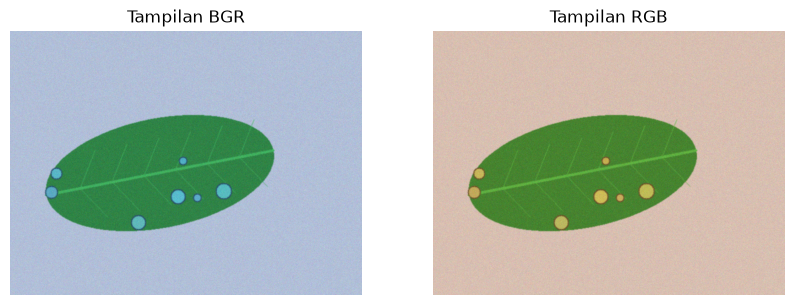

In [5]:
# Menampilkan gambar dengan Matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Tampilan BGR")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_rgb)
plt.title("Tampilan RGB")
plt.axis("off")

plt.show()

## Problem Statement

Daun teh dapat mengalami gangguan berupa bercak pada
permukaannya. Kondisi bercak tersebut dapat memiliki tingkat
keparahan yang berbeda, mulai dari kondisi sehat, bercak
ringan, hingga bercak parah.

Pemeriksaan secara manual membutuhkan pengamatan langsung
dan berpotensi menghasilkan penilaian yang berbeda antara
satu pengamat dengan pengamat lainnya.

Oleh karena itu, diperlukan pendekatan Computer Vision
untuk membantu mengolah citra daun teh dan mengidentifikasi
karakteristik visual yang berkaitan dengan kondisi bercak.

Pada praktikum ini digunakan dataset sintetis yang terdiri
dari citra daun teh sehat, bercak ringan, dan bercak parah.
Tahapan pengolahan citra akan digunakan sebagai dasar untuk
mempersiapkan citra sebelum dilakukan analisis lebih lanjut.

## Pipeline Computer Vision

Pipeline Computer Vision yang digunakan dalam studi kasus
SIMUTEH terdiri dari enam tahapan:

1. Image Acquisition
   Mengambil atau memperoleh citra daun teh.

2. Preprocessing
   Melakukan perbaikan citra seperti pengubahan ukuran,
   peningkatan kontras, dan pengurangan noise.

3. Image Representation
   Merepresentasikan citra melalui kanal warna dan
   karakteristik intensitas piksel.

4. Feature Extraction
   Mengambil karakteristik visual yang dapat membedakan
   daun sehat dan daun yang memiliki bercak.

5. Classification / Analysis
   Menganalisis karakteristik citra untuk mengetahui
   kondisi daun teh.

6. Evaluation
   Mengevaluasi hasil pengolahan berdasarkan kualitas
   citra dan kesesuaian hasil analisis.

## Responsible Computer Vision

Penggunaan Computer Vision perlu memperhatikan beberapa
risiko agar hasil pengolahan citra tidak menimbulkan
kesimpulan yang keliru.

## Responsible Computer Vision

| Risiko | Dampak | Upaya Mitigasi |
|---|---|---|
| Dataset sintetis tidak mewakili kondisi nyata | Hasil analisis belum tentu sesuai dengan daun teh asli | Melakukan pengujian menggunakan citra nyata |
| Pencahayaan tidak konsisten | Warna bercak dapat terlihat berbeda | Menggunakan pencahayaan yang terkontrol |
| Kualitas gambar rendah | Detail bercak sulit diamati | Menggunakan resolusi citra yang memadai |
| Kesalahan pelabelan | Analisis kondisi daun menjadi tidak tepat | Memeriksa kembali label dataset |
| Hasil sistem dianggap selalu benar | Pengguna dapat mengambil keputusan yang keliru | Menyertakan keterbatasan sistem dan pemeriksaan manusia |

## Jawaban Pertanyaan P1

P1.1 – Semantic Gap

Petugas sortir melihat daun teh secara langsung dan dapat mengenali warna, bentuk, serta bercak pada daun. Sementara itu, komputer hanya menerima data berupa angka piksel. Contohnya, pada koordinat (100, 200) diperoleh nilai piksel BGR sebesar [192 196 217]. Nilai tersebut perlu diolah agar komputer dapat membedakan daun sehat dan daun yang memiliki bercak.

P1.2 – Sumber Variasi

Tiga sumber variasi yang paling mungkin mengganggu SIMUTEH adalah:

1. Pencahayaan: Perbedaan cahaya dapat mengubah tampilan warna daun. Ditangani pada tahap preprocessing melalui penyesuaian kecerahan dan kontras.
2. Sudut pandang: Posisi kamera dapat memengaruhi bentuk dan posisi bercak yang terlihat. Ditangani pada tahap image acquisition dan preprocessing.
3. Derau dan latar belakang: Gangguan pada gambar dapat menghambat pengamatan bercak. Ditangani pada tahap preprocessing melalui filtering dan segmentasi.

P1.3 – Konversi BGR ke RGB

OpenCV menggunakan urutan warna BGR, sedangkan Matplotlib menggunakan RGB. Tanpa konversi, warna gambar dapat terlihat berbeda karena urutan kanal warna tertukar. Jika kesalahan ini terbawa ke perhitungan fitur warna pada P9, nilai fitur dapat menjadi tidak sesuai sehingga memengaruhi hasil analisis dan identifikasi daun.

P1.4 – Nilai Adil dan Amanah

Jika daun sehat dinilai sebagai bercak berat, petani atau pemasok dapat dirugikan karena daun berkualitas baik dianggap buruk. Sebaliknya, jika daun bercak berat dinilai sehat, petugas sortir dan pembeli dapat dirugikan karena kualitas daun tidak sesuai kenyataan.

Nilai adil berarti sistem harus memberikan penilaian secara objektif dan tidak merugikan pihak tertentu. Nilai amanah berarti hasil penilaian harus dapat dipercaya, transparan, dan tetap diperiksa oleh manusia.